In [8]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [9]:
# Physiologically acceptable range of HR and distances between R.
# Signals outside of it are treated like acquisition error and filtered out.
PHYSIO_HR = np.array([30, 200])
PHYSIO_RR = (60 / PHYSIO_HR)[::-1]
PHYSIO_RR


array([0.3, 2. ])

In [10]:
# Download from https://physionet.org/content/nsr2db/1.0.0/
# normal-sinus-rhythm-rr-interval-database-1.0.0/

# Download from https://physionet.org/content/chf2db/1.0.0/
# congestive-heart-failure-rr-interval-database-1.0.0/

In [11]:
import wfdb
from DFA import dfa

# Annotation symbols that mark a heartbeat (non-beat ones like '~' are skipped)
BEAT_SYMBOLS = list("NLRBAaJSVrFejnE/fQ?")


def load_rr(record_path: Path):
    ann = wfdb.rdann(str(record_path), "ecg")
    is_beat = np.isin(ann.symbol, BEAT_SYMBOLS)
    RR = np.diff(ann.sample[is_beat]) / ann.fs
    return RR

In [12]:
def run_on_db(dir_path: Path):
    records = sorted(path.stem for path in dir_path.iterdir() if path.name.endswith(".ecg"))

    alpha1s, alpha2s = [], []
    for record in records:
        _, alpha1, alpha2, _, _ = dfa(load_rr(dir_path / record))
        alpha1s.append(alpha1)
        alpha2s.append(alpha2)

    return records, np.array(alpha1s), np.array(alpha2s)

In [13]:
nsr_records, nsr_alpha1, nsr_alpha2 = run_on_db(Path("data/normal-sinus-rhythm-rr-interval-database-1.0.0"))
chf_records, chf_alpha1, chf_alpha2 = run_on_db(Path("data/congestive-heart-failure-rr-interval-database-1.0.0"))

print(f"NSR2DB: {len(nsr_records)} records, alpha1={nsr_alpha1.mean():.3f}±{nsr_alpha1.std():.3f}, alpha2={nsr_alpha2.mean():.3f}±{nsr_alpha2.std():.3f}")
print(f"CHF2DB: {len(chf_records)} records, alpha1={chf_alpha1.mean():.3f}±{chf_alpha1.std():.3f}, alpha2={chf_alpha2.mean():.3f}±{chf_alpha2.std():.3f}")

NSR2DB: 54 records, alpha1=1.174±0.203, alpha2=1.000±0.096
CHF2DB: 29 records, alpha1=0.699±0.257, alpha2=0.898±0.213


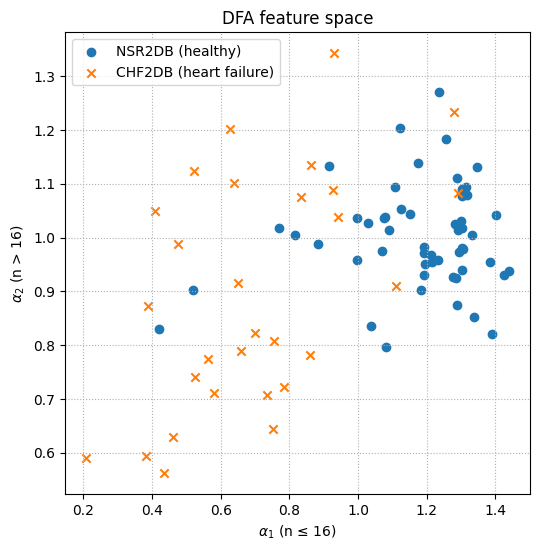

In [14]:
plt.figure(figsize=(6, 6))
plt.scatter(nsr_alpha1, nsr_alpha2, marker="o", label="NSR2DB (healthy)")
plt.scatter(chf_alpha1, chf_alpha2, marker="x", label="CHF2DB (heart failure)")
plt.xlabel(r"$\alpha_1$ (n ≤ 16)")
plt.ylabel(r"$\alpha_2$ (n > 16)")
plt.title("DFA feature space")
plt.grid(True, linestyle=":")
plt.legend()
plt.show()